# Steps


1. Read the external text file and split it into chunks.
2. Initialize an embedding model.
3. Generate embeddings for each chunk.
4. Generate embedding of the query ( QE).
5. Generate a similarity score betweent QE and each of the Chunk embeddings.
6. Extract top K chunks based on similarity score.
7. Frame a prompt with the query and the top-k chunks.
8. Prompt an LLM with the prompt framed in step-7.

[Link](https://medium.com/@mahakal001/building-a-rag-pipeline-step-by-step-0a5e1ac68562)

## Extract

In [ ]:
%pip install pdfplumber
%pip install pymupdf



In [2]:
import fitz

doc = fitz.open("DPR_Final V1.pdf")
text = ""
for page in doc:
    text += str(page.get_text())


In [1]:
import pdfplumber

doc = pdfplumber.open("DPR_Final V1.pdf")
text = ""
for page in doc.pages:
    text += str(page.extract_text())
    

In [ ]:
text.replace(".","")
print(text.split())

In [3]:
import re
text = re.sub(r"\.{2,}", "", text)
# print(text.split())

## Chunking 
https://jillanisofttech.medium.com/optimizing-chunking-strategies-for-retrieval-augmented-generation-rag-applications-with-python-c3ab5060d3e4

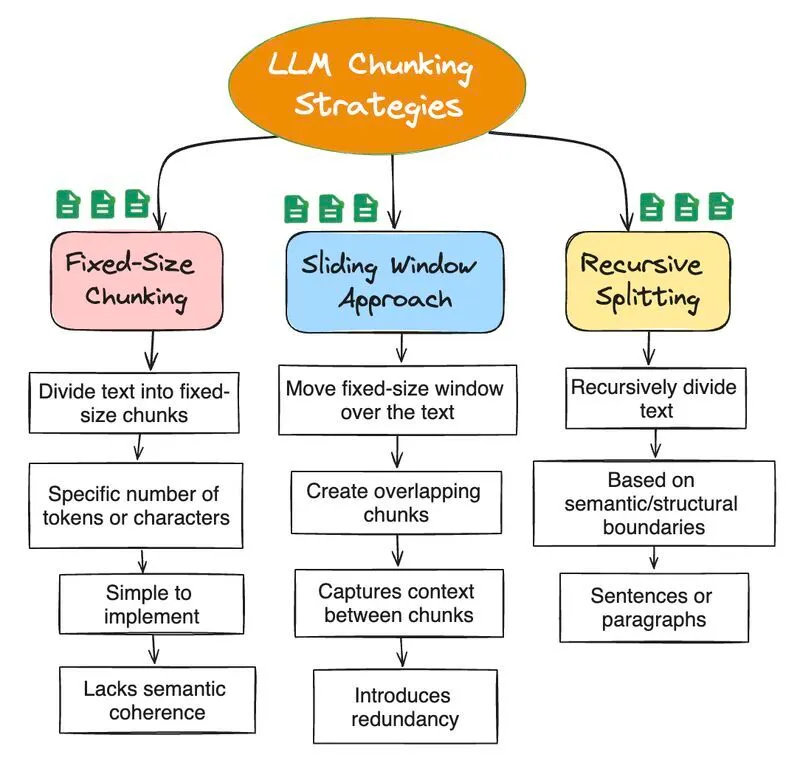

### Fixed-Size Chunking

> 1. Text is split into words.
> 2. A chunks list is created where chunk by chunk is appended
> 3. A token based rule is implemented where the number of tokens are limited in a chunk

In [ ]:
def fixed_size_chunking(text, max_tokens):
    words = text.split()
    chunks = []
    curr_chunk = []
    curr_tokens = 0
    
    for word in words:
        curr_tokens += len(word.split())
        if curr_tokens <= max_tokens:
            curr_chunk.append(word)
        else:
            chunks.append(' '.join(curr_chunk))
            curr_chunk = [word]
            curr_tokens = len(word.split())
    
    if curr_chunk:
        chunks.append(' '.join(curr_chunk))
    
    return chunks

max_tokens = 1000
chunks = fixed_size_chunking(text,max_tokens)
for i, chunk in enumerate(chunks):
    print(f"Chunk {i+1}: {chunk}\n")
print(len(chunks))
        

### Sliding Window Chunking

> 1. Text is split into words.
> 2. A chunks list is created where chunk by chunk is appended
> 3. An overlapping concept is used where a same piece of text is present in different chunks.
> 4. Use of start, end and overlap_size to maintain a window that gets updated everytime a chunk is appended hence appending a fixed chunk_size

In [ ]:
def sliding_window_chunking(text,chunk_size,overlap):
    words = text.split()
    chunks = []
    start = 0
    
    while start < len(words):
        end = start + chunk_size
        chunks.append(' '.join(words[start:end]))
        start += chunk_size - overlap
    
    return chunks

chunks = sliding_window_chunking(text,1000,500)
for i, chunk in enumerate(chunks):
    print(f"Chunk {i}: {chunk}\n")

### Recursive Splitting

> 1. Uses NLTK's Punkt Unsupervised Model to judge the sentence boundaries.
> 2. Same max_tokens approach for chunking.

In [ ]:
import nltk
def recursive_splitting(text, max_tokens):
    nltk.download('punkt_tab')
    sentences = nltk.sent_tokenize(text)
    chunks = []
    curr_chunk = []
    curr_tokens = 0
    
    for sentence in sentences:
        sentence_tokens = len(sentence.split())
        if curr_tokens + sentence_tokens <= max_tokens:
            curr_chunk.append(sentence)
            curr_tokens += sentence_tokens
        else:
            chunks.append(' '.join(curr_chunk))
            curr_chunk = [sentence]
            curr_tokens = sentence_tokens
            
    if curr_chunk:
        chunks.append(' '.join(curr_chunk))
    
    return chunks

chunks = recursive_splitting(text,500)
for i, chunk in enumerate(chunks):
    print(f"Chunk {i}: {chunk}\n\n")

### Semantic Chunking

In [ ]:
%pip install sentence-transformers

In [ ]:
from sentence_transformers import SentenceTransformer, util
import nltk

def semantic_chunking(text, max_tokens, model_name='all-MiniLM-L6-v2'):
    model = SentenceTransformer(model_name)
    sentences = nltk.sent_tokenize(text)
    embeddings = model.encode(sentences, convert_to_tensor=True)
    chunks = []
    current_chunk = []
    current_tokens = 0
    current_embedding = None
    current_count = 0

    for i, sentence in enumerate(sentences):
        sentence_tokens = len(sentence.split())
        if current_tokens + sentence_tokens <= max_tokens:
            current_chunk.append(sentence)
            current_tokens += sentence_tokens

            if current_embedding is None:
                current_embedding = embeddings[i]
                current_count = 1
            else:
                current_count += 1
                current_embedding = (current_embedding * (current_count - 1) + embeddings[i]) / current_count

            # Optional: compute similarity without overwriting current_embedding
            # sim = util.cos_sim(current_embedding.unsqueeze(0), embeddings[i].unsqueeze(0)).item()
        else:
            chunks.append(' '.join(current_chunk))
            current_chunk = [sentence]
            current_tokens = sentence_tokens
            current_embedding = embeddings[i]
            current_count = 1

    if current_chunk:
        chunks.append(' '.join(current_chunk))

    return chunks

chunks = semantic_chunking(text, 500)
for i, chunk in enumerate(chunks):
    print(f"Chunk {i}: \n{chunk}\n")